In [123]:
# compare unassociated LAT sources with H-alpha distributions
# plot distributions of population parameters on the sky
# conda activate gammapy-1.2
import numpy as np
import pandas as pd
from matplotlib import pyplot
import healpy
print(healpy.__version__)
import astropy
from astropy.io import fits
from astropy import units as u
from astropy.coordinates import SkyCoord
import astropy.coordinates as coord



import gammapy
#from gammapy.datasets import MapDataset
#from gammapy.makers import MapDatasetMaker, SafeMaskMaker
from gammapy.maps import Map, MapAxis, WcsGeom, WcsNDMap, HpxGeom, HpxNDMap


import os
import sys
if '../../lib/' not in sys.path:
    sys.path.append('../../lib/')
import dio3
import multi_fgl_utils as util
import plot_util as putil


1.16.6


In [124]:
folder_out = '../../results/gas_correlations/'
if not os.path.isdir(folder_out):
    os.makedirs(folder_out)

In [125]:

plots_folder_paper = '/Users/Dmitry/Work/Fermi/fermi_multiclass_papers/6_GU_paper\
/plots/'
if not os.path.isdir(plots_folder_paper):
    os.mkdir(plots_folder_paper)


In [126]:
script_fn = 'fermi_multiclass/notebooks/star_forming/unas_vs_halpha.ipynb'
fig_meta = {'Author': 'Dmitry Malyshev', 'Subject': script_fn}
plots_folder = '../../plots/gas_correlations/'
if not os.path.isdir(plots_folder):
    os.makedirs(plots_folder)
    
save_correlations = True
save_plots = 0
save_png = 0
copy2tex = 0
#pars_dict={'legend.fontsize': 12}
#pars_dict={'right': 0.82}
#pars_dict={'left': 0.02}
pars_dict={'fig_size':[12, 4],
            'legend.fontsize': 12,
           'top': 0.97,
           'bottom': 0.06,
          'right': 0.87,
          'left': 0.1}

putil.setup_figure_pars(pars_dict)


0

In [127]:
# load SFR associations by David Smith
select_SFRs = True
if select_SFRs:
    fn = '../../data_in/SFRs/obj-sfr-lat_v44.fits'
    hdu = fits.open(fn)

In [128]:
hdu[1].data['name2'][:10]

chararray([' --', ' --', ' --', ' --', ' --', ' --', ' --', ' --', ' --',
           ' --'], dtype='<U23')

In [129]:
hdu[1].header

XTENSION= 'BINTABLE'           / binary table extension                         
BITPIX  =                    8 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                  215 / length of dimension 1                          
NAXIS2  =                11155 / length of dimension 2                          
PCOUNT  =                    0 / number of group parameters                     
GCOUNT  =                    1 / number of groups                               
TFIELDS =                   11 / number of table fields                         
TTYPE1  = 'name1   '                                                            
TFORM1  = '18A     '                                                            
TTYPE2  = 'name2   '                                                            
TFORM2  = '23A     '                                                            
TTYPE3  = 'GLON    '        

In [130]:
# load Halpha map
fn = '../../data_in/halpha/lambda_halpha_fwhm06_0512.fits'
hdu = fits.open(fn)
halpha_data = hdu[1].data['TEMPERATURE']
nside = hdu[1].header['NSIDE']
nest = hdu[1].header['ORDERING'] == 'NESTED'
geom = HpxGeom(nside, frame='galactic', nest=nest)
halpha = HpxNDMap(geom, halpha_data, unit='')
print(nside, nest)

#halpha = HpxNDMap.read(fn, hdu=1)

512 True


In [131]:
# Planck dust map
fn = '../../data_in/planck_gas/COM_CompMap_dust-commander_0256_R2.00.fits'
hdu = fits.open(fn)
#hdu[1].header
dust_data = hdu[1].data['I_ML']
nside_dust = hdu[1].header['NSIDE']
nest_dust = hdu[1].header['ORDERING'] == 'NESTED'
geom_dust = HpxGeom(nside_dust, frame='galactic', nest=nest_dust)
dust = HpxNDMap(geom_dust, dust_data, unit='')
dust = dust.interp_to_geom(geom, preserve_counts=False)
#print(nside)

In [132]:
#load CO map
folder = '/Users/Dmitry/data/Galprop_webrun/PJM_ApJ_846_67_2017_and_JPM_ApJ_856_61_2018_data_files/'
fn = folder + 'rbands_co22mm_2001_8deg.fits.gz'
hdu_CO = fits.open(fn)
nr, ny, nx = hdu_CO[0].data.shape
psize = 360./nx
pos = SkyCoord(0, 0, unit='deg', frame='galactic')
geom_CO = WcsGeom.create(skydir=pos, npix=(nx, ny), binsz=psize, frame='galactic')
CO_data = np.sum(hdu_CO[0].data, axis=0)
CO_data = np.heaviside(CO_data, 0.) * CO_data
CO_map = WcsNDMap(data=CO_data, geom=geom_CO)
CO_map_hpix = CO_map.interp_to_geom(geom)
print(nside)

512


In [133]:
geom

In [134]:
folder = '/Users/Dmitry/Work/Fermi/Fermi_MC/data/gas_maps/'
fn = folder + 'eb-v_corrected_py_rbands_hi_6.2.0_Ts150_zmax1_Rsl8_sl_0.5_\
res4_sel2_OptThinLim_ringfit_noCO_mag2.0_d2CO_0.0480_d2HI_0.0145.fits.gz'
hdu_HI = fits.open(fn)
geom_HI = WcsGeom.from_header(hdu_HI[0].header)
HI_data = np.sum(hdu_HI[0].data, axis=0)
HI_map = WcsNDMap(data=HI_data, geom=geom_HI)
HI_map_hpix = HI_map.interp_to_geom(geom)

In [135]:
if 0:
    log_halphap = HpxNDMap(geom, np.log10(halpha_data), unit='')
    #pyplot.figure(figsize=[10,6])
    pyplot.figure()
    log_halphap.plot(vmin=1., vmax=2, add_cbar=True)

In [136]:

model = 'prior' #'prior', 'cov'
#baseline_case = '4FGL-DR4_GMM_RF'
baseline_case = '4FGL-DR4_2class_RF' # '4FGL-DR4_GMM_RF', '4FGL-DR4_2class_RF'
root_folder = '../../'
config_folder = root_folder + 'config/'
cat_name = '4FGL-DR4'


if model  == 'prior':
    case = '4FGL-DR4_2class_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4'
    #case = '4FGL-DR4_GMM_PDF_no_coord_no_bcu_spp_pshift_nGauss1_npar4'
    #folder = '../../results/4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_probabilistic_catalogs/'
    #fn = folder + '4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_unas_unk_prior_shift_npar4_1Gauss_prob_cat.csv'
    alg = 'PDF'
    add_pshift = 1
else:
    case = '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp'
    #folder = '../../results/4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_probabilistic_catalogs/'
    #fn = folder + '4FGL-DR4_v34_4classes_GMM_no_bcu_spp_no_coord_features_prob_cat.csv'
    alg = 'RF'
    add_pshift = 0

# generic inputs
cdict = util.get_config_dict(cat_name=cat_name, 
                             baseline_case=baseline_case, 
                             case=case, 
                             folder=config_folder)

cdict['root_folder'] = root_folder

folder_out = '%sresults/%s_probabilistic_catalogs/' % (root_folder, util.get_cat_descr(cdict, add_pshift=0))
fn = '%s%s_%s' % (folder_out, util.get_cat_descr(cdict, add_pshift=add_pshift), 'prob_cat.csv')

summary_fn = fn.replace('prob_cat.csv', 'summary.csv')
cat_df = pd.read_csv(fn, index_col=0)
sum_df = pd.read_csv(summary_fn, index_col=0)
sum_df

,Class label,Node,Physical classes,N assoc,PDF assoc,"PDF unas,unk,bcu,spp"
Group,,,,,,
1,bll+,0.0,"bll, fsrq, rdg, agn, ssrq, css, nlsy1, sey",2390.0,1407.2,1499.3
2,msp+,1.0,"psr, msp, gc, pwn, snr, glc, sfr, hmb, lmb, bi...",477.0,470.1,794.2
3,Gauss,NaN,Gauss,0.0,433.7,1254.5


In [137]:
#amask = (cat_df['CLASS1'] != 'unas')
unas_type = 'unas' # 'unas', 'unk', bcu', 'spp', 'all_not_assoc'
descr_str_folder = util.get_cat_descr(cdict)
descr_str = '%s_%s' % (descr_str_folder, unas_type)

#plots_folder = '%s/plots/mclass/dNdS_%s/' % (root_folder, descr_str_folder)
#print(plots_folder)
#if not os.path.isdir(plots_folder):
#    os.mkdir(plots_folder)


umask = ((cat_df['CLASS1'] == unas_type))
#sdf = cat_df[umask]

In [138]:

# transform to lon and lat
if 'GLON' in cat_df.columns and 'GLON' in cat_df.columns:
    lons = cat_df['GLON']
    lats = cat_df['GLAT']
else:
    z = np.array(cat_df['sin(GLAT)'])
    x = np.array(cat_df['cos(GLON)']) * np.sqrt(1 - z**2)
    y = np.array(cat_df['sin(GLON)']) * np.sqrt(1 - z**2)
    lons, lats = healpy.vec2ang(np.array([x, y, z]).T, lonlat=True)
llat = False
hlat = True
bmask = 15.
if llat:
    smask = np.abs(lats) < bmask
    smask_str = '_b<%ideg' % bmask
elif hlat:
    smask = np.abs(lats) > bmask
    smask_str = '_b>%ideg' % bmask
else:
    smask = np.ones(lats, dtype=bool)
    smask_str = ''
    
ufn_out = '%s%s_shift_model_gas_correlations_unas%s.csv' % (folder_out, model, smask_str)
afn_out = '%s%s_shift_model_gas_correlations_assoc%s.csv' % (folder_out, model, smask_str)


pixels = healpy.ang2pix(nside, lons, lats, nest=nest, lonlat=True)
upixels = pixels[umask & smask]


In [139]:
pearson_corr = lambda x, y: np.corrcoef(x, y)[0,1]
linear_corr = lambda x, y: np.sum(x * y) / np.sum(1. * x)
weighted_corr = lambda x, y: np.sum(x * (y - np.mean(y))) / np.sum(x)

In [140]:
clabels

{1: 'extragal', 2: 'Galactic', 'Gauss': 'SGU-like', 'uncertain': 'uncertain'}

In [141]:
cols = list(range(1, len(sum_df)))
if model == 'prior':
    cols.append('Gauss')
clabels = {col:sum_df['Class label'].iloc[ind] for ind,col in enumerate(cols)}
if case.find('2class') > -1:
    for key in clabels.keys():
        clabels[key] = clabels[key].replace('bll+', 'extragal')
        clabels[key] = clabels[key].replace('msp+', 'Galactic')
clabels['uncertain'] = 'uncertain'
clabels['Gauss'] = 'SGU-like'
#print(clabels)

#corr = weighted_corr
corr = linear_corr
print('Correlations of unassociated sources')
print('Class\thalpha\tHI\tCO\tdust\t# of sources')
for ind, col in enumerate(cols):
    #print(col)
    col_name = '%s_%s' % (col, alg)
    probs = cat_df[col_name][umask & smask]
    ha_corr = corr(probs, halpha_data[upixels])
    HI_corr = corr(probs, HI_map_hpix.data[upixels])
    CO_corr = corr(probs, CO_map_hpix.data[upixels])
    dust_corr = corr(probs, dust.data[upixels])

    print('%s \t%.2f \t%.2f \t%.2f \t%.2f \t%.1f' % \
          (sum_df['Class label'].iloc[ind], ha_corr, HI_corr, CO_corr, dust_corr, np.sum(probs)))

Correlations of unassociated sources
Class	halpha	HI	CO	dust	# of sources
bll+ 	3.12 	5.59 	0.06 	90.83 	438.3
msp+ 	3.61 	6.73 	0.06 	116.24 	212.0
Gauss 	6.00 	11.34 	0.19 	241.49 	173.6


In [142]:
clms = ['Class', 'H-alpha', 'HI', 'CO', 'dust', 'sources']
class_name = 'CLASS1'
#inds = range(1, 7)
df_out = pd.DataFrame(columns=clms, index=cols)
df_out['Class'] = list(sum_df['Class label'])# + ['assoc']
corr_data = {'H-alpha':halpha_data[pixels], 
             'HI':HI_map_hpix.data[pixels], 
             'CO':CO_map_hpix.data[pixels],
            'dust':dust.data[pixels]}
adf_out = df_out.copy()
if 'Gauss' in adf_out.index:
    adf_out.drop(labels='Gauss', inplace=True)

for ind, col in enumerate(cols):
    col_name = '%s_%s' % (col, alg)
    #print(col_name)
    probs = cat_df[col_name]
    
    cls = sum_df['Physical classes'].iloc[ind].split(', ')
    amask = util.get_cl_mask(cls, cat_df, cname=class_name)

    for key, data in corr_data.items():
        df_out[key].iloc[ind] = corr(probs[umask & smask], data[umask & smask])
        if col != 'Gauss':
            adf_out[key].iloc[ind] = corr(probs[amask & smask], data[amask & smask])
        

        
        
    df_out['sources'].iloc[ind] = np.sum(probs)
    if col != 'Gauss':
        adf_out['sources'].iloc[ind] = np.sum(amask & smask)

if save_correlations:
    print('Unas')
    print(df_out)
    print(ufn_out)
    print('Assoc')
    print(adf_out)
    print(afn_out)
    df_out.to_csv(ufn_out)
    adf_out.to_csv(afn_out)


Unas
       Class   H-alpha        HI        CO        dust      sources
1       bll+   3.11718  5.586457  0.057391     90.8286  2906.499658
2       msp+   3.60868  6.728215  0.055244  116.235033  1264.389224
Gauss  Gauss  5.995673  11.33609   0.19107  241.489719  1688.111118
../../results/4FGL-DR4_v34_2classes_2class_gal_egal_no_bcu_spp_no_coord_features_probabilistic_catalogs/prior_shift_model_gas_correlations_unas_b>15deg.csv
Assoc
  Class   H-alpha        HI        CO        dust sources
1  bll+  1.857982  4.301186  0.050463   62.513149    1681
2  msp+  8.675133  5.997678   0.10465  102.418851     139
../../results/4FGL-DR4_v34_2classes_2class_gal_egal_no_bcu_spp_no_coord_features_probabilistic_catalogs/prior_shift_model_gas_correlations_assoc_b>15deg.csv


In [143]:
# cutout a patch along the Gal plane
Lwidth = 180
Bwidth = 50
L0 = 0. #360. - Lwidth/2
B0 = 0.
pos = SkyCoord(L0, B0, unit='deg', frame='galactic')
width = [Lwidth * u.deg, Bwidth * u.deg]
geom_2d = WcsGeom.create(skydir=pos, width=width, binsz=0.1, frame='galactic')
halpha_patch = halpha.interp_to_geom(geom_2d)
HI_patch = HI_map.interp_to_geom(geom_2d)
CO_patch = CO_map.interp_to_geom(geom_2d)
dust_patch = dust.interp_to_geom(geom_2d)

In [144]:
cols

[1, 2, 'Gauss']

In [145]:
colors = {1: 'blue', 2:'grey', 3:'y', 4:'r', 'Gauss':'g', 'uncertain':'darkorchid'}
markers = {1: '^', 2:'v', 3:'o', 4:'d', 'Gauss':'s', 'uncertain':'x'}
if case.find('2class') > -1:
    colors = {1: 'blue', 2:'r', 'Gauss':'g', 'uncertain':'darkorchid'}

#inds = [5]
cols_df = list(range(1, len(sum_df)))
if model == 'prior':
    cols_df.insert(0, 'Gauss')

#if model  == 'prior':
#    cols_df = ['Gauss',1, 2, 3, 4]
    cols_show = cols_df + ['uncertain']
#else:
#    cols_df = [1, 2, 3, 4]
cols_show = cols_df + ['uncertain']
cols = ['%s_%s' % (col, alg) for col in cols_df]

stretch = 'sqrt'
cmap = "Blues"
p_thres = 0.5


Gauss_PDF SGU-like
1172
653
1_PDF extragal
1481
368
2_PDF Galactic
515
289
2_PDF uncertain
240
99


Text(0.5, 1.0, 'H alpha, prior shift')

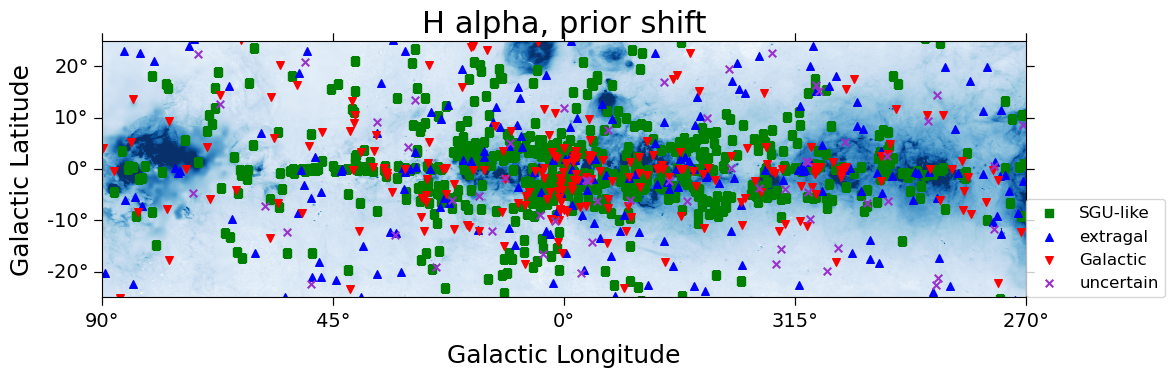

In [146]:
ms = 30
#pyplot.figure(figsize=[10,6])
pyplot.figure()
halpha_patch.plot(add_cbar=0, vmax=100, stretch=stretch, cmap=cmap, alpha=1)

for ind, col in enumerate(cols_show):
    if col == 'uncertain':
        pmask = np.max(cat_df[cols], axis=1) < p_thres
    else:
        col_name = '%s_%s' % (col, alg)
        pmask = cat_df[col_name] > p_thres
    print(col_name, clabels[col])

    lmax = L0 + geom_2d.width[0][0].value / 2.
    lmin = L0 - geom_2d.width[0][0].value / 2.
    bmin = B0 - geom_2d.width[1][0].value / 2.
    dphi = geom_2d.width[0][0].value / geom_2d.npix[0][0]

    pmask &= ((lons > lmin) & (lons < lmax)) | ((lons > lmin + 360.) & (lons < lmax + 360.))
    plons = lons[pmask & umask]
    plons_shift = plons - 360.
    plats = lats[pmask & umask]
    print(sum(pmask))
    print(sum(pmask & umask))


    lpix = (lmax - plons) / dphi - 0.5
    lpix_shift = (lmax - plons_shift) / dphi - 0.5
    bpix = (plats - bmin) / dphi - 0.5
    pyplot.scatter(lpix, bpix, s=ms, c=colors[col], marker=markers[col], label=clabels[col])
    pyplot.scatter(lpix_shift, bpix, s=ms, c=colors[col], marker=markers[col])
pyplot.legend(loc=(1, 0))
pyplot.title('H alpha, %s shift' % model)

Text(0.5, 1.0, 'HI, prior shift')

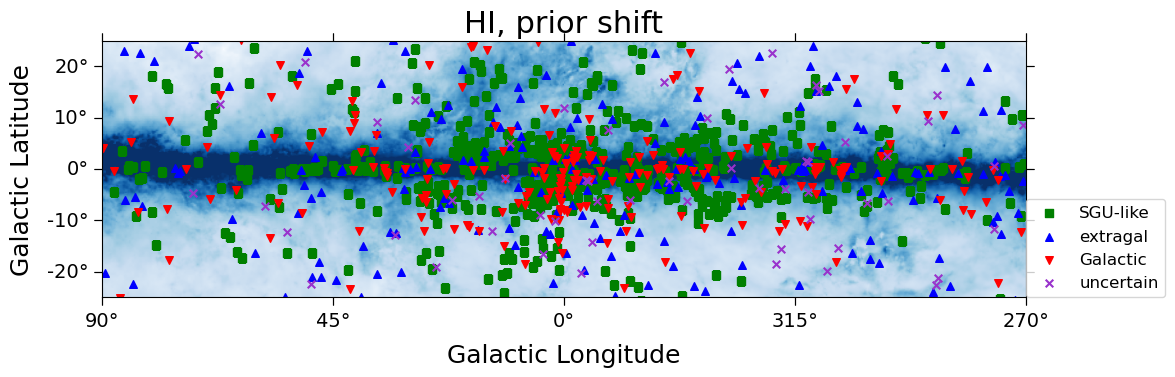

In [147]:
ms = 30
#pyplot.figure(figsize=[10,6])
pyplot.figure()
HI_patch.plot(add_cbar=0, vmax=100, stretch=stretch, cmap=cmap)


for ind, col in enumerate(cols_show):
    if col == 'uncertain':
        pmask = np.max(cat_df[cols], axis=1) < p_thres
    else:
        col_name = '%s_%s' % (col, alg)
        pmask = cat_df[col_name] > p_thres

    lmax = L0 + geom_2d.width[0][0].value / 2.
    lmin = L0 - geom_2d.width[0][0].value / 2.
    bmin = B0 - geom_2d.width[1][0].value / 2.
    dphi = geom_2d.width[0][0].value / geom_2d.npix[0][0]

    pmask &= ((lons > lmin) & (lons < lmax)) | ((lons > lmin + 360.) & (lons < lmax + 360.))
    plons = lons[pmask & umask]
    plons_shift = plons - 360.
    plats = lats[pmask & umask]


    lpix = (lmax - plons) / dphi - 0.5
    lpix_shift = (lmax - plons_shift) / dphi - 0.5
    bpix = (plats - bmin) / dphi - 0.5
    pyplot.scatter(lpix, bpix, s=ms, c=colors[col], marker=markers[col], label=clabels[col])
    pyplot.scatter(lpix_shift, bpix, s=ms, c=colors[col], marker=markers[col])
pyplot.legend(loc=(1, 0))
pyplot.title('HI, %s shift' % model)

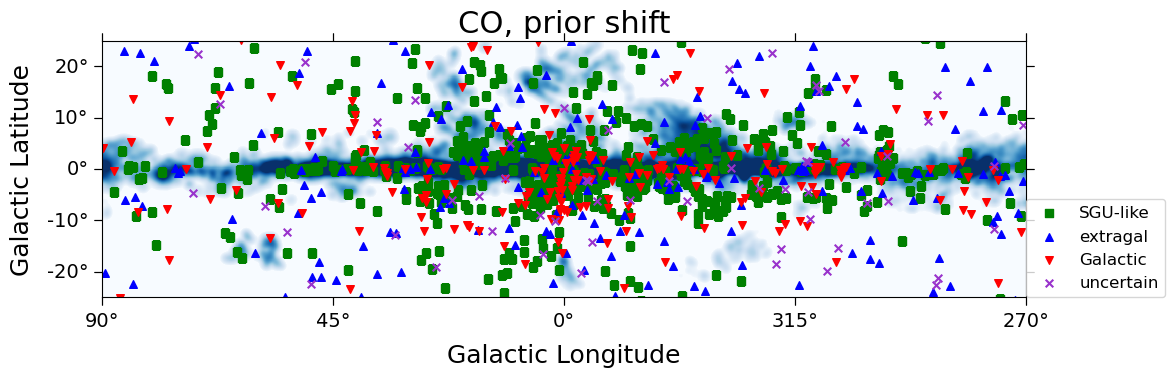

In [148]:
ms = 30
#pyplot.figure(figsize=[10,6])
pyplot.figure()
if 0:
    halpha_patch.plot(add_cbar=0, vmin=0.1, vmax=100, stretch=stretch, cmap=cmap, alpha=1)
    pyplot.contour(CO_patch.smooth('0.5 deg').data, levels=np.linspace(5, 20, 4), alpha=0.7)
    pyplot.title('Halpha + CO, %s shift' % model)
else:
    CO_patch.smooth('0.5 deg').plot(add_cbar=0, vmin=0.1, vmax=20, stretch=stretch, cmap=cmap)
    #CO_patch.plot(add_cbar=1, vmin=0.1, vmax=20, stretch=stretch, cmap=cmap)
    pyplot.title('CO, %s shift' % model)

for ind, col in enumerate(cols_show):
    if col == 'uncertain':
        pmask = np.max(cat_df[cols], axis=1) < p_thres
    else:
        col_name = '%s_%s' % (col, alg)
        pmask = cat_df[col_name] > p_thres

    lmax = L0 + geom_2d.width[0][0].value / 2.
    lmin = L0 - geom_2d.width[0][0].value / 2.
    bmin = B0 - geom_2d.width[1][0].value / 2.
    dphi = geom_2d.width[0][0].value / geom_2d.npix[0][0]

    pmask &= ((lons > lmin) & (lons < lmax)) | ((lons > lmin + 360.) & (lons < lmax + 360.))
    plons = lons[pmask & umask]
    plons_shift = plons - 360.
    plats = lats[pmask & umask]


    lpix = (lmax - plons) / dphi - 0.5
    lpix_shift = (lmax - plons_shift) / dphi - 0.5
    bpix = (plats - bmin) / dphi - 0.5
    pyplot.scatter(lpix, bpix, s=ms, c=colors[col], marker=markers[col], label=clabels[col])
    pyplot.scatter(lpix_shift, bpix, s=ms, c=colors[col], marker=markers[col])
pyplot.legend(loc=(1, 0))


save figure to file: ../../plots/gas_correlations//source_distribution_prior_L0=0_Bmax=25.pdf


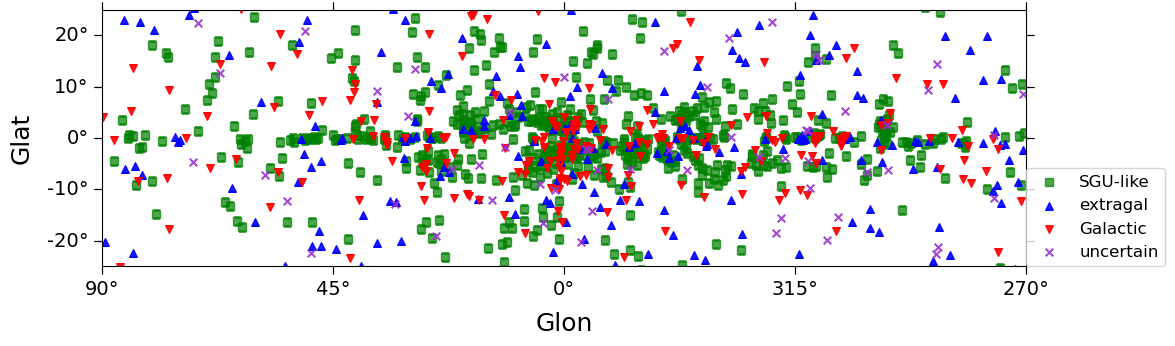

In [149]:
show_dust = 0
ms = 30
pyplot.figure()
if not show_dust:
    dust_patch_empty = dust_patch.copy()
    dust_patch_empty *= 0.
    dust_patch_empty.plot(add_cbar=0, vmin=0, vmax=1, stretch=stretch, cmap='Greys', alpha=1)
else:
    dust_patch.plot(add_cbar=0, vmax=2000, stretch=stretch, cmap=cmap, alpha=1)

for ind, col in enumerate(cols_show):
    if col == 'uncertain':
        pmask = np.max(cat_df[cols], axis=1) < p_thres
    else:
        col_name = '%s_%s' % (col, alg)
        pmask = cat_df[col_name] > p_thres
    
    if col == 'Gauss':
        alpha = 0.7
    else:
        alpha = 0.9

    lmax = L0 + geom_2d.width[0][0].value / 2.
    lmin = L0 - geom_2d.width[0][0].value / 2.
    bmin = B0 - geom_2d.width[1][0].value / 2.
    dphi = geom_2d.width[0][0].value / geom_2d.npix[0][0]

    pmask &= ((lons > lmin) & (lons < lmax)) | ((lons > lmin + 360.) & (lons < lmax + 360.))
    plons = lons[pmask * umask]
    plons_shift = plons - 360.
    plats = lats[pmask * umask]


    lpix = (lmax - plons) / dphi - 0.5
    lpix_shift = (lmax - plons_shift) / dphi - 0.5
    bpix = (plats - bmin) / dphi - 0.5
    pyplot.scatter(lpix, bpix, s=ms, c=colors[col], marker=markers[col], label=clabels[col], alpha=alpha)
    pyplot.scatter(lpix_shift, bpix, s=ms, c=colors[col], marker=markers[col], alpha=alpha)
pyplot.legend(loc=(1, 0))
if show_dust:
    pyplot.title('Dust, %s shift classification' % model)
pyplot.xlabel('Glon')
pyplot.ylabel('Glat')

save_plots = 1
copy2tex = 0
if save_plots:
    if show_dust:
        fn = '%s/gas_correlations_map_dust_%s_L0=%i_Bmax=%i.pdf' % (plots_folder, model, L0, Bwidth/2)
    else:
        fn = '%s/source_distribution_%s_L0=%i_Bmax=%i.pdf' % (plots_folder, model, L0, Bwidth/2)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    if copy2tex:
        fn_paper = fn.replace(plots_folder, plots_folder_paper)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)
    if save_png:
        fn = fn.replace('.pdf', '.png')
        pyplot.savefig(fn, metadata=fig_meta)


In [150]:
if 0:
    #import astropy.coordinates as coord
    from astrotools import coord, skymap 
    #import astropy.units as u

    #fig = pyplot.figure(figsize=[10,6])
    fig = pyplot.figure()
    vecs = coord.ang2vec(np.deg2rad(lons), np.deg2rad(lats))
    p = skymap.scatter(vecs, alpha=1)

    if 0:
        for ind, col in enumerate(cols_show):
            if col == 'uncertain':
                pmask = np.max(cat_df[cols], axis=1) < p_thres
            else:
                col_name = '%s_%s' % (col, alg)
                pmask = cat_df[col_name] > p_thres
            plons = np.deg2rad(lons[pmask])
            plats = np.deg2rad(lats[pmask])

            #skymap.scatter(vecs, fig=fig, c=colors[col], marker=markers[col], label=clabels[col])


            pyplot.scatter(-plons, plats, c=colors[col], marker=markers[col], label=clabels[col])


SGU-like 873
extragal 690
Galactic 350
uncertain 144
save figure to file: ../../plots/gas_correlations//unas_classes_skymap_4FGL-DR4_v34_2classes_2class_gal_egal_no_bcu_spp_no_coord_features_unas.pdf


0

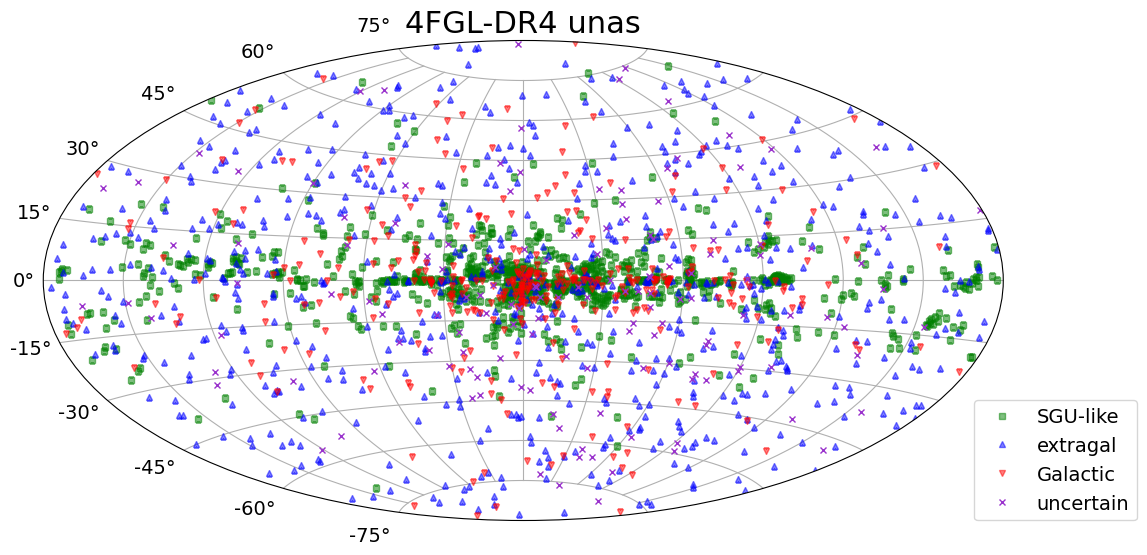

In [151]:
pars_dicta={'legend.fontsize': 14,
           'top': 0.9,
           'bottom': 0.1,
          'right': 0.9,
          'left': 0.05}
putil.setup_figure_pars(pars_dicta)

fig = pyplot.figure(figsize=(12, 6))
ax = fig.add_subplot(111, projection="aitoff")
if 0:
    coordinates = coord.SkyCoord(np.array(lons), np.array(lats), unit='deg', frame='galactic')
    plons = coordinates.galactic.l.wrap_at('180d').rad
    plats = coordinates.galactic.b.rad
    ax.plot(-plons, plats, 'k.', alpha=1, ms=1)
else:
    for ind, col in enumerate(cols_show):
        if col == 'uncertain':
            pmask = np.max(cat_df[cols], axis=1) < p_thres
        else:
            col_name = '%s_%s' % (col, alg)
            pmask = cat_df[col_name] > p_thres
        pmask &= umask
        
        print(clabels[col], sum(pmask))
        
        if clabels[col] == 'Gauss':
            ms = 4.
            alpha = 0.5
        elif clabels[col] == 'uncertain':
            ms = 4
            alpha = 1.
        else:
            ms = 4
            alpha = 0.5
        coordinates = coord.SkyCoord(np.array(lons[pmask]), np.array(lats[pmask]), 
                                     unit='deg', frame='galactic')
        plons = coordinates.galactic.l.wrap_at('180d').rad
        plats = coordinates.galactic.b.rad
        ax.plot(-plons, plats, ls='', ms=ms, c=colors[col], marker=markers[col], 
                label=clabels[col], alpha=alpha)
ax.set_xticklabels([])
ax.grid(True)
pyplot.legend(loc=(0.97, 0))
pyplot.title('4FGL-DR4 unas')


save_plots = 1
copy2tex = 0
if save_plots:
    fn = '%s/unas_classes_skymap_%s.pdf' % (plots_folder, descr_str)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    fn_png = fn.replace('.pdf', '.png')
    if save_png:
        pyplot.savefig(fn_png, metadata=fig_meta)
    if copy2tex:
        fn_paper = fn.replace(plots_folder, plots_folder_paper)
        cmd = 'cp %s %s' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)

putil.setup_figure_pars(pars_dict)

In [152]:
markers

{1: '^', 2: 'v', 3: 'o', 4: 'd', 'Gauss': 's', 'uncertain': 'x'}

In [153]:
clabels

{1: 'extragal', 2: 'Galactic', 'Gauss': 'SGU-like', 'uncertain': 'uncertain'}

In [154]:
plots_folder_paper

'/Users/Dmitry/Work/Fermi/fermi_multiclass_papers/6_GU_paper/plots/'